# Multi-label news classification

This notebook implements the solution proposed in the written exam for the multi-label news categories classification, based on a multi-input deep neural network combining text (Bidirectional LSTM), Bag-of-Words (MLP), and metadata (year, month).

In [ ]:
import string
import zipfile
import pickle as pk
import itertools
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, initializers
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.utils import to_categorical, plot_model
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, multilabel_confusion_matrix

In [ ]:
#Download and unzip the dataset, load the pickle, and print basic stats (shapes, ranges, label distribution)
!wget -q https://frasca.di.unimi.it/MLDNN/input_data.zip

with zipfile.ZipFile("input_data.zip", 'r') as zip_ref:
    zip_ref.extractall("unzipped_data")

with open("unzipped_data/input_data.pkl", "rb") as f:
    data = pk.load(f)

texts  = data["texts"]
years  = data["years"]
months = data["months"]
X_bow  = data["X_bow"]
Y      = data["labels"]

print("N samples:", len(texts))
print("Types:", type(texts), type(years), type(months))
print("X_bow shape:", X_bow.shape, "| dtype:", X_bow.dtype)
print("Y shape:", Y.shape, "| dtype:", Y.dtype)

print("\nYear range:", min(years), "-", max(years))
print("Month range:", min(months), "-", max(months))

word_counts = [len(t.split()) for t in texts]
print("\nWord count - min:", min(word_counts), "max:", max(word_counts), "mean:", round(np.mean(word_counts), 2))

labels_per_sample = Y.sum(axis=1)
print("\nLabels per sample - min:", labels_per_sample.min(), "max:", labels_per_sample.max(), "mean:", round(labels_per_sample.mean(), 2))
print("Samples per label - min:", Y.sum(axis=0).min(), "max:", Y.sum(axis=0).max())

print("\nExample text:", texts[0])
print("Example year/month:", years[0], months[0])
print("Example labels:", Y[0])

#Number of K labels
NUM_LABELS = Y.shape[1]
print("Number of labels (K):", NUM_LABELS)

N samples: 11000
Types: <class 'list'> <class 'list'> <class 'list'>
X_bow shape: (11000, 10000) | dtype: int64
Y shape: (11000, 18) | dtype: int64

Year range: 2012 - 2022
Month range: 1 - 12

Word count - min: 1 max: 100 mean: 27.79

Labels per sample - min: 2 max: 3 mean: 2.27
Samples per label - min: 1000 max: 4000

Example text: The 10 Most Beautiful Places in Croatia As one of Europe's most popular beach destinations and blessed with year-round sun, Croatia's historic towns and idyllic islands have a wealth of natural attractions to offer. From rolling vineyards to sweeping coastal cliffs, here are 10 of the most beautiful places in Croatia to add to your itinerary.
Example year/month: 2014 3
Example labels: [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0]
Number of labels (K): 18


# 1. MODEL CHOICE

I implement a multi-input model with 4 branches, because the input types have different nature
and need different processing:
- Text -> Embedding + Bidirectional LSTM. An LSTM keeps the relations between distant words, which a plain MLP would lose, and its gates avoid the vanishing gradient of standard RNNs. I read it in both directions (bidirectional) to use the context before and after each word.
- BoW -> MLP. The BoW is high-dimensional (10000) but informative; an MLP (a universal approximator) with ReLU compresses it and captures non-linear patterns.
- Year, Month -> metadata preprocessed and fed directly to the concatenation.

The 4 branches are then concatenated into a single representation for the final classification layer.


###Train / Validation / Test split

I split the dataset into Train/Validation/Test with an 80/10/10 ratio. The split is performed here, before preprocessing, so that the vocabulary and the scalers are fit on the training set only (no leakage).


In [ ]:
#80/10/10 random split into train/val/test (by index, so every input shares the same split) + cast labels to float32
N = len(texts)
indices = np.arange(N)

idx_trainval, idx_test = train_test_split(indices, test_size=0.10, random_state=213, shuffle=True)
idx_train, idx_val = train_test_split(idx_trainval, test_size=1/9, random_state=213, shuffle=True)

def select(idx):
    return {
        "texts":  [texts[i] for i in idx],
        "years":  [years[i] for i in idx],
        "months": [months[i] for i in idx],
        "X_bow":  X_bow[idx],
        "Y":      Y[idx],
    }

train_raw = select(idx_train)
val_raw   = select(idx_val)
test_raw  = select(idx_test)

Y_train = train_raw["Y"]
Y_val   = val_raw["Y"]
Y_test  = test_raw["Y"]

Y_train = Y_train.astype("float32")
Y_val   = Y_val.astype("float32")
Y_test  = Y_test.astype("float32")

print("Train:", len(idx_train), "| Val:", len(idx_val), "| Test:", len(idx_test))
print("Train label frequency per class:", Y_train.sum(axis=0))
print("Val label frequency per class:  ", Y_val.sum(axis=0))
print("Test label frequency per class: ", Y_test.sum(axis=0))

Train: 8800 | Val: 1100 | Test: 1100
Train label frequency per class: [ 782.  792.  782.  792.  814.  782.  788. 1573.  803. 3203. 1617.  811.
 1614.  807.  792.  803.  820. 1617.]
Val label frequency per class:   [ 97. 114.  97. 114.  95.  97.  98. 203.  95. 407. 190. 105. 200. 106.
  92.  95. 103. 190.]
Test label frequency per class:  [121.  94. 121.  94.  91. 121. 114. 224. 102. 390. 193.  84. 186.  87.
 116. 102.  77. 193.]


**CHANGE:** In my written solution I had proposed a stratified split, but I was not able to keep it in the implementation, for a technical reason. The stratification used in the labs
(train_test_split(stratify=...)) works only on a one-dimensional label vector, while here the task
is multi-label and Y is a 2-D matrix with 18 columns: there is no way to ask stratify= to keep
the proportions of all 18 labels balanced at the same time. A proper multi-label stratification would
require an external library (iterative-stratification or scikit-multilearn). For this reason I opted for a standard random split, fixing the seed (random_state=213)
to make it reproducible. I would also note that, as the per-class label frequencies printed above
show, the random split still keeps comparable label proportions across the three sets.

# 2. INPUT

## a. Preprocessing


Preprocessing is performed separately for each branch:
- Year -> Min-Max Scaling to [0, 1]. The raw year (2012-2022) has a large magnitude compared to the other inputs. If features are on very different scales, the large ones dominate the gradient. Min-Max maps it to [0, 1], so it's comparable to the other inputs and training is more stable.

- Month -> the month is categorical with no ordinal meaning
(December is not "greater" than January). An integer encoding would impose a false order/distance that the network might exploit. One-Hot removes this, and with only 12 categories it's not expensive.

- Text

  Text cleaning / normalization + tokenization -> any "-" is replaced by a space, the text is lowercased, and punctuation, symbols and non-alphabetical tokens are removed. The cleaned text is then split on whitespace into a sequence of word tokens, which is what the Embedding and the LSTM work on. This collapses surface variants of the same word into a single token and drops non-informative characters, which shrinks the vocabulary and reduces sparsity, so the Embedding learns from cleaner and more frequent tokens.
  
  Vocabulary construction and pruning -> a vocabulary is built from the training tokens and pruned: very rare words are mapped to `<UNK>` because they mostly add noise, overfit, and bloat the embedding table; very common words are also mapped to `<UNK>` since they are shared across all classes and carry little discriminative signal. Pruning bounds the vocabulary size and lets the model handle words unseen at training time (they too become `<UNK>`).
  
  Integer Encoding -> each remaining word is mapped to a unique integer, because the Embedding layer takes integer indices as input (not raw strings).

  Padding / truncating to a fixed length MAX_LEN = 28 (the mean length of 27.8 words, not the max of 100): padding to 100 would make most sequences mostly `<PAD>`, wasting computation and diluting the signal, while 28 covers an average news and truncates only the rare very long ones.

- Bag-of-Words -> Min-Max Scaling to [0, 1]. Same scale motivation as the year: raw counts vary widely and would otherwise enter the MLP with uneven magnitudes. I use Min-Max (not standardization) because the counts are non-negative and Min-Max keeps zeros at 0, so a 0 still means the word doesn't appear.

In [ ]:
# Text cleaning + word tokenization
PUNCT_TABLE = str.maketrans('', '', string.punctuation)

def clean_text(text):
    text = text.replace("-", " ")
    tokens = text.split()
    tokens = [t.translate(PUNCT_TABLE) for t in tokens]
    tokens = [t for t in tokens if t.isalpha()]
    tokens = [t.lower() for t in tokens]
    return tokens

train_tokens = [clean_text(t) for t in train_raw["texts"]]
val_tokens   = [clean_text(t) for t in val_raw["texts"]]
test_tokens  = [clean_text(t) for t in test_raw["texts"]]

print("Example tokens:", train_tokens[0][:15])

Example tokens: ['be', 'your', 'familys', 'chief', 'security', 'officer', 'i', 'wont', 'lie', 'this', 'kind', 'of', 'vigilance', 'requires', 'a']


In [ ]:
#Build and prune the vocabulary
all_words = [w for tokens in train_tokens for w in tokens]
print(f"Total words (train only): {len(all_words)}")
print(f"Unique words (train only): {len(set(all_words))}")

word_freq = Counter(all_words)

N_MOST_COMMON_TO_DROP = 15
MIN_FREQUENCY = 5
VOCAB_SIZE = 10000

most_common_words = set(w for w, _ in word_freq.most_common(N_MOST_COMMON_TO_DROP))
vocab_words = [w for w, c in word_freq.items() if c >= MIN_FREQUENCY and w not in most_common_words]
vocab_words = sorted(vocab_words, key=lambda w: word_freq[w], reverse=True)[:VOCAB_SIZE]
vocab_words = np.array(sorted(vocab_words))

word2idx = dict((w, i + 2) for i, w in enumerate(vocab_words))
word2idx["<PAD>"] = 0
word2idx["<UNK>"] = 1

print(f"Final vocabulary size (incl. PAD/UNK): {len(word2idx)}")

MAX_LEN = 28

#Integer Encoding for each token
def encode(tokens):
    return [word2idx.get(w, word2idx["<UNK>"]) for w in tokens]

#Padding / truncating sequences to MAX_LEN (= 28)
X_text_train = pad_sequences([encode(t) for t in train_tokens], maxlen=MAX_LEN, padding="post", truncating="post", value=0)
X_text_val   = pad_sequences([encode(t) for t in val_tokens],   maxlen=MAX_LEN, padding="post", truncating="post", value=0)
X_text_test  = pad_sequences([encode(t) for t in test_tokens],  maxlen=MAX_LEN, padding="post", truncating="post", value=0)

Total words (train only): 241475
Unique words (train only): 23186
Final vocabulary size (incl. PAD/UNK): 5816


In [ ]:
#Year: Min-Max scaling
year_scaler = MinMaxScaler()
X_year_train = year_scaler.fit_transform(np.array(train_raw["years"]).reshape(-1, 1).astype(np.float32))
X_year_val   = year_scaler.transform(np.array(val_raw["years"]).reshape(-1, 1).astype(np.float32))
X_year_test  = year_scaler.transform(np.array(test_raw["years"]).reshape(-1, 1).astype(np.float32))

#Month: One-Hot Encoding
X_month_train = to_categorical(np.array(train_raw["months"]) - 1, num_classes=12)
X_month_val   = to_categorical(np.array(val_raw["months"]) - 1, num_classes=12)
X_month_test  = to_categorical(np.array(test_raw["months"]) - 1, num_classes=12)

#BoW: Min-Max scaling
bow_scaler = MinMaxScaler()
X_bow_train = bow_scaler.fit_transform(train_raw["X_bow"]).astype(np.float32)
X_bow_val   = bow_scaler.transform(val_raw["X_bow"]).astype(np.float32)
X_bow_test  = bow_scaler.transform(test_raw["X_bow"]).astype(np.float32)

train_inputs = {"text_input": X_text_train, "bow_input": X_bow_train, "year_input": X_year_train, "month_input": X_month_train}
val_inputs   = {"text_input": X_text_val,   "bow_input": X_bow_val,   "year_input": X_year_val,   "month_input": X_month_val}
test_inputs  = {"text_input": X_text_test,  "bow_input": X_bow_test,  "year_input": X_year_test,  "month_input": X_month_test}

## b. Input shapes (after preprocessing)

- Text: shape (B, 28), integer token IDs -> after the Embedding layer: shape (B, 28, d), where d is the embedding dimension. The Embedding maps each word to a small dense vector that the model learns during training. A one-hot vector would be huge and wouldn't capture word similarity. d is one of the tuned hyperparameters.
- Bag-of-Words: shape (B, 10000), float values in [0, 1].
- Year: shape (B, 1), float value in [0, 1].
- Month: shape (B, 12), one-hot binary vector.

**CHANGE**: I made mistakes in these shapes in the written exam, which I correct here. The preprocessing techniques themselves are unchanged from the written solution, only the resulting shapes were stated incorrectly, and I'm correcting them here for consistency with the rest of the notebook.

In [ ]:
print("Train - text:", X_text_train.shape, "/ bow:", X_bow_train.shape, "/ year:", X_year_train.shape, "/ month:", X_month_train.shape, "/ Y:", Y_train.shape)
print("Val   - text:", X_text_val.shape,   "/ bow:", X_bow_val.shape,   "/ year:", X_year_val.shape,   "/ month:", X_month_val.shape,   "/ Y:", Y_val.shape)
print("Test  - text:", X_text_test.shape,  "/ bow:", X_bow_test.shape,  "/ year:", X_year_test.shape,  "/ month:", X_month_test.shape,  "/ Y:", Y_test.shape)

Train - text: (8800, 28) / bow: (8800, 10000) / year: (8800, 1) / month: (8800, 12) / Y: (8800, 18)
Val   - text: (1100, 28) / bow: (1100, 10000) / year: (1100, 1) / month: (1100, 12) / Y: (1100, 18)
Test  - text: (1100, 28) / bow: (1100, 10000) / year: (1100, 1) / month: (1100, 12) / Y: (1100, 18)


# 3. OUTPUT and LOSS

This task is a multi-label classification (each news entry can belong to more than one of the K = 18 possible subjects simultaneously). The output layer will then be a Dense(18, activation="sigmoid") layer: the Sigmoid gives an independent probability in [0,1] for each of the 18 subjects. I use Sigmoid, not Softmax, because the labels are not mutually exclusive.

As loss function, I use Binary Cross-Entropy, since each of the 18 labels can be treated as its own independent binary classification problem (subject present / not present), consistent with the Sigmoid output above.

# 4. MODEL CONFIGURATION

## a.

- Text branch: raw text -> preprocessing (cleaning, integer encoding, padding) -> Embedding -> Bidirectional LSTM.
- BoW branch: Bag-of-Words vector -> Dense -> (Dropout) -> Dense -> (Dropout)-> Dense -> (Dropout).
- Year branch: Min-Max scaled scalar.
- Month branch: One-Hot vector.

--> Concatenate all 4 branches -> Dense -> Dropout -> Dense (18 neurons, Sigmoid).

In [ ]:
VOCAB_SIZE_FINAL  = len(word2idx)

seed = 213
def setRandomSeed(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

he_init = initializers.HeNormal()
glorot_init = initializers.GlorotUniform()

def build_model(learning_rate, dropout_rate, embedding_dim, lstm_units, bow_units):

    #Text branch: Embedding + Bidirectional LSTM
    text_input = layers.Input(shape=(MAX_LEN,), name="text_input")
    x_text = layers.Embedding(input_dim=VOCAB_SIZE_FINAL, output_dim=embedding_dim)(text_input)
    x_text = layers.Bidirectional(layers.LSTM(lstm_units, activation="tanh", kernel_initializer=glorot_init))(x_text)

    #BoW branch: MLP that compresses the 10000-dim vector
    bow_input = layers.Input(shape=(X_bow_train.shape[1],), name="bow_input")
    x_bow = layers.Dense(bow_units, activation="relu", kernel_initializer=he_init)(bow_input)
    x_bow = layers.Dropout(dropout_rate)(x_bow)
    x_bow = layers.Dense(bow_units // 2, activation="relu", kernel_initializer=he_init)(x_bow)
    x_bow = layers.Dropout(dropout_rate)(x_bow)
    x_bow = layers.Dense(bow_units // 4, activation="relu", kernel_initializer=he_init)(x_bow)
    x_bow = layers.Dropout(dropout_rate)(x_bow)

    #Metadata branches: fed directly to the concatenation
    year_input = layers.Input(shape=(1,), name="year_input")
    month_input = layers.Input(shape=(12,), name="month_input")

    #Concatenation + classification head
    concat = layers.Concatenate()([x_text, x_bow, year_input, month_input])
    x = layers.Dense(64, activation="relu", kernel_initializer=he_init)(concat)
    x = layers.Dropout(dropout_rate)(x)
    output = layers.Dense(NUM_LABELS, activation="sigmoid")(x) # 18 independent Sigmoids (multi-label)

    model = models.Model(inputs=[text_input, bow_input, year_input, month_input],
                          outputs=output, name="multilabel_news_classifier")
    model.compile(
      optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
      loss="binary_crossentropy",
      metrics=[tf.keras.metrics.F1Score(average="macro", threshold=0.5)]
    )
    return model

## b. Model configuration to optimize performance
- ReLU + He init in the Dense hidden layers. ReLU adds non-linearity but zeroes the negative half, halving the signal variance; He compensates exactly for this, keeping the variance stable across layers.

- tanh + Glorot/Xavier initialization in the LSTM -> tanh is the standard recurrent activation (bounded, zero-centred). Being symmetric it doesn't discard signal, so Glorot/Xavier is the matching
  initializer that preserves variance.
- Adam (learning rate = 0.001) combines momentum (smoother/faster updates) and RMSProp (per-parameter adaptive step), so it handles the very different scales of our branches with no manual tuning, so I keep the default 0.001.
- Dropout after each BoW Dense and before the output: the BoW branch has by far the most parameters (first Dense maps 10000 inputs), so it overfits most -> dropout forces more robust features, so the neurons don't co-adapt. The final model is also Early-Stopped on the validation loss.
- Hyperparameter tuning -> the architecture is fixed, so the only real lever is the capacity of the three learned representations -> embedding_dim (quality of the word vectors), lstm_units (how much sequential context the text
branch holds), bow_units (capacity of the largest branch, which dominates the parameter count).
Together they set the capacity/overfitting trade-off (what matters most for how well it generalizes). The rest is fixed because it matters less: learning rate at Adam's default (Adam self-adapts), dropout = 0.3 and batch size = 64 are standard values affecting mainly training speed/noise, not capacity.
I picked two values per hyperparameter (a small and a large one) instead of random numbers: embedding_dim in {50,100}, lstm_units in {64,128}, bow_units in {128,256} -> 2x2x2 = 8 configs, enough to see the effect while staying cheap.

To respect the 5-minute runtime constraint, I only tune the hyperparameters with the largest expected impact on performance (embedding dimension, LSTM units, and BoW layer size) and fix the rest (learning rate, batch size and dropout) to usual values. The grid search itself uses few candidate values and few training epochs per configuration, just enough to compare them, not to fully converge. For the same reason, Early Stopping in the final training uses a low patience, so training stops quickly once the model stops improving instead of running for many epochs.


In [ ]:
#Hyperparameter tuning

train_arrays = [train_inputs["text_input"], train_inputs["bow_input"], train_inputs["year_input"], train_inputs["month_input"]]
val_arrays   = [val_inputs["text_input"], val_inputs["bow_input"], val_inputs["year_input"], val_inputs["month_input"]]

LEARNING_RATE = 1e-3
BATCH_SIZE = 64
DROPOUT_RATE = 0.3

embedding_dims  = [50, 100]
lstm_units_list = [64, 128]
bow_units_list  = [128, 256]

results = []

for ed, lu, bu in itertools.product(embedding_dims, lstm_units_list, bow_units_list):
    setRandomSeed(seed)
    candidate = build_model(learning_rate=LEARNING_RATE, dropout_rate=DROPOUT_RATE, embedding_dim=ed, lstm_units=lu, bow_units=bu)
    candidate.fit(train_arrays, Y_train, epochs=8, batch_size=BATCH_SIZE, verbose=0)

    val_pred = candidate.predict(val_arrays, verbose=0)
    val_pred_bin = (val_pred >= 0.5).astype(int)
    score = f1_score(Y_val, val_pred_bin, average="macro")

    config = {"embedding_dim": ed, "lstm_units": lu, "bow_units": bu}
    results.append({**config, "val_f1": score})
    print(f"Macro F1 score: {score:.4f} \t with: {config}")

best = max(results, key=lambda r: r["val_f1"])
best_config = {k: v for k, v in best.items() if k != 'val_f1'}
print(f"\nBest -> Macro F1 score: {best['val_f1']:.4f}  with: {best_config}")

BEST_EMBED_DIM = best["embedding_dim"]
BEST_LSTM_UNITS = best["lstm_units"]
BEST_BOW_UNITS = best["bow_units"]

Macro F1 score: 0.6995 	 with: {'embedding_dim': 50, 'lstm_units': 64, 'bow_units': 128}
Macro F1 score: 0.6968 	 with: {'embedding_dim': 50, 'lstm_units': 64, 'bow_units': 256}
Macro F1 score: 0.7011 	 with: {'embedding_dim': 50, 'lstm_units': 128, 'bow_units': 128}
Macro F1 score: 0.6964 	 with: {'embedding_dim': 50, 'lstm_units': 128, 'bow_units': 256}
Macro F1 score: 0.6801 	 with: {'embedding_dim': 100, 'lstm_units': 64, 'bow_units': 128}
Macro F1 score: 0.6904 	 with: {'embedding_dim': 100, 'lstm_units': 64, 'bow_units': 256}
Macro F1 score: 0.6813 	 with: {'embedding_dim': 100, 'lstm_units': 128, 'bow_units': 128}
Macro F1 score: 0.6850 	 with: {'embedding_dim': 100, 'lstm_units': 128, 'bow_units': 256}

Best -> Macro F1 score: 0.7011  with: {'embedding_dim': 50, 'lstm_units': 128, 'bow_units': 128}


I run the grid search over the 8 configurations and keep the one with the best validation Macro-F1, which I then retrain below.

In [ ]:
#Build the final model with the best hyperparameters
setRandomSeed(seed)
model = build_model(learning_rate=LEARNING_RATE, embedding_dim=BEST_EMBED_DIM, dropout_rate=DROPOUT_RATE,
                     lstm_units=BEST_LSTM_UNITS, bow_units=BEST_BOW_UNITS)
model.summary()

Model: "multilabel_news_classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ bow_input           │ (None, 10000)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_40 (Dense)    │ (None, 128)       │  1,280,128 │ bow_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_32          │ (None, 128)       │          0 │ dense_40[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_41 (Dense)    │ (None, 64)        │      8,256 │ dropout_32[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 28)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_33          │ (None, 64)        │          0 │ dense_41[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_8         │ (None, 28, 50)    │    290,800 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_42 (Dense)    │ (None, 32)        │      2,080 │ dropout_33[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_8     │ (None, 256)       │    183,296 │ embedding_8[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_34          │ (None, 32)        │          0 │ dense_42[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ year_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ month_input         │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 301)       │          0 │ bidirectional_8[… │
│ (Concatenate)       │                   │            │ dropout_34[0][0], │
│                     │                   │            │ year_input[0][0], │
│                     │                   │            │ month_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_43 (Dense)    │ (None, 64)        │     19,328 │ concatenate_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_35          │ (None, 64)        │          0 │ dense_43[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_44 (Dense)    │ (None, 18)        │      1,170 │ dropout_35[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,785,058 (6.81 MB)

 Trainable params: 1,785,058 (6.81 MB)

 Non-trainable params: 0 (0.00 B)

The graphical sketch of this pipeline is generated by plot_model below, after the model is built.

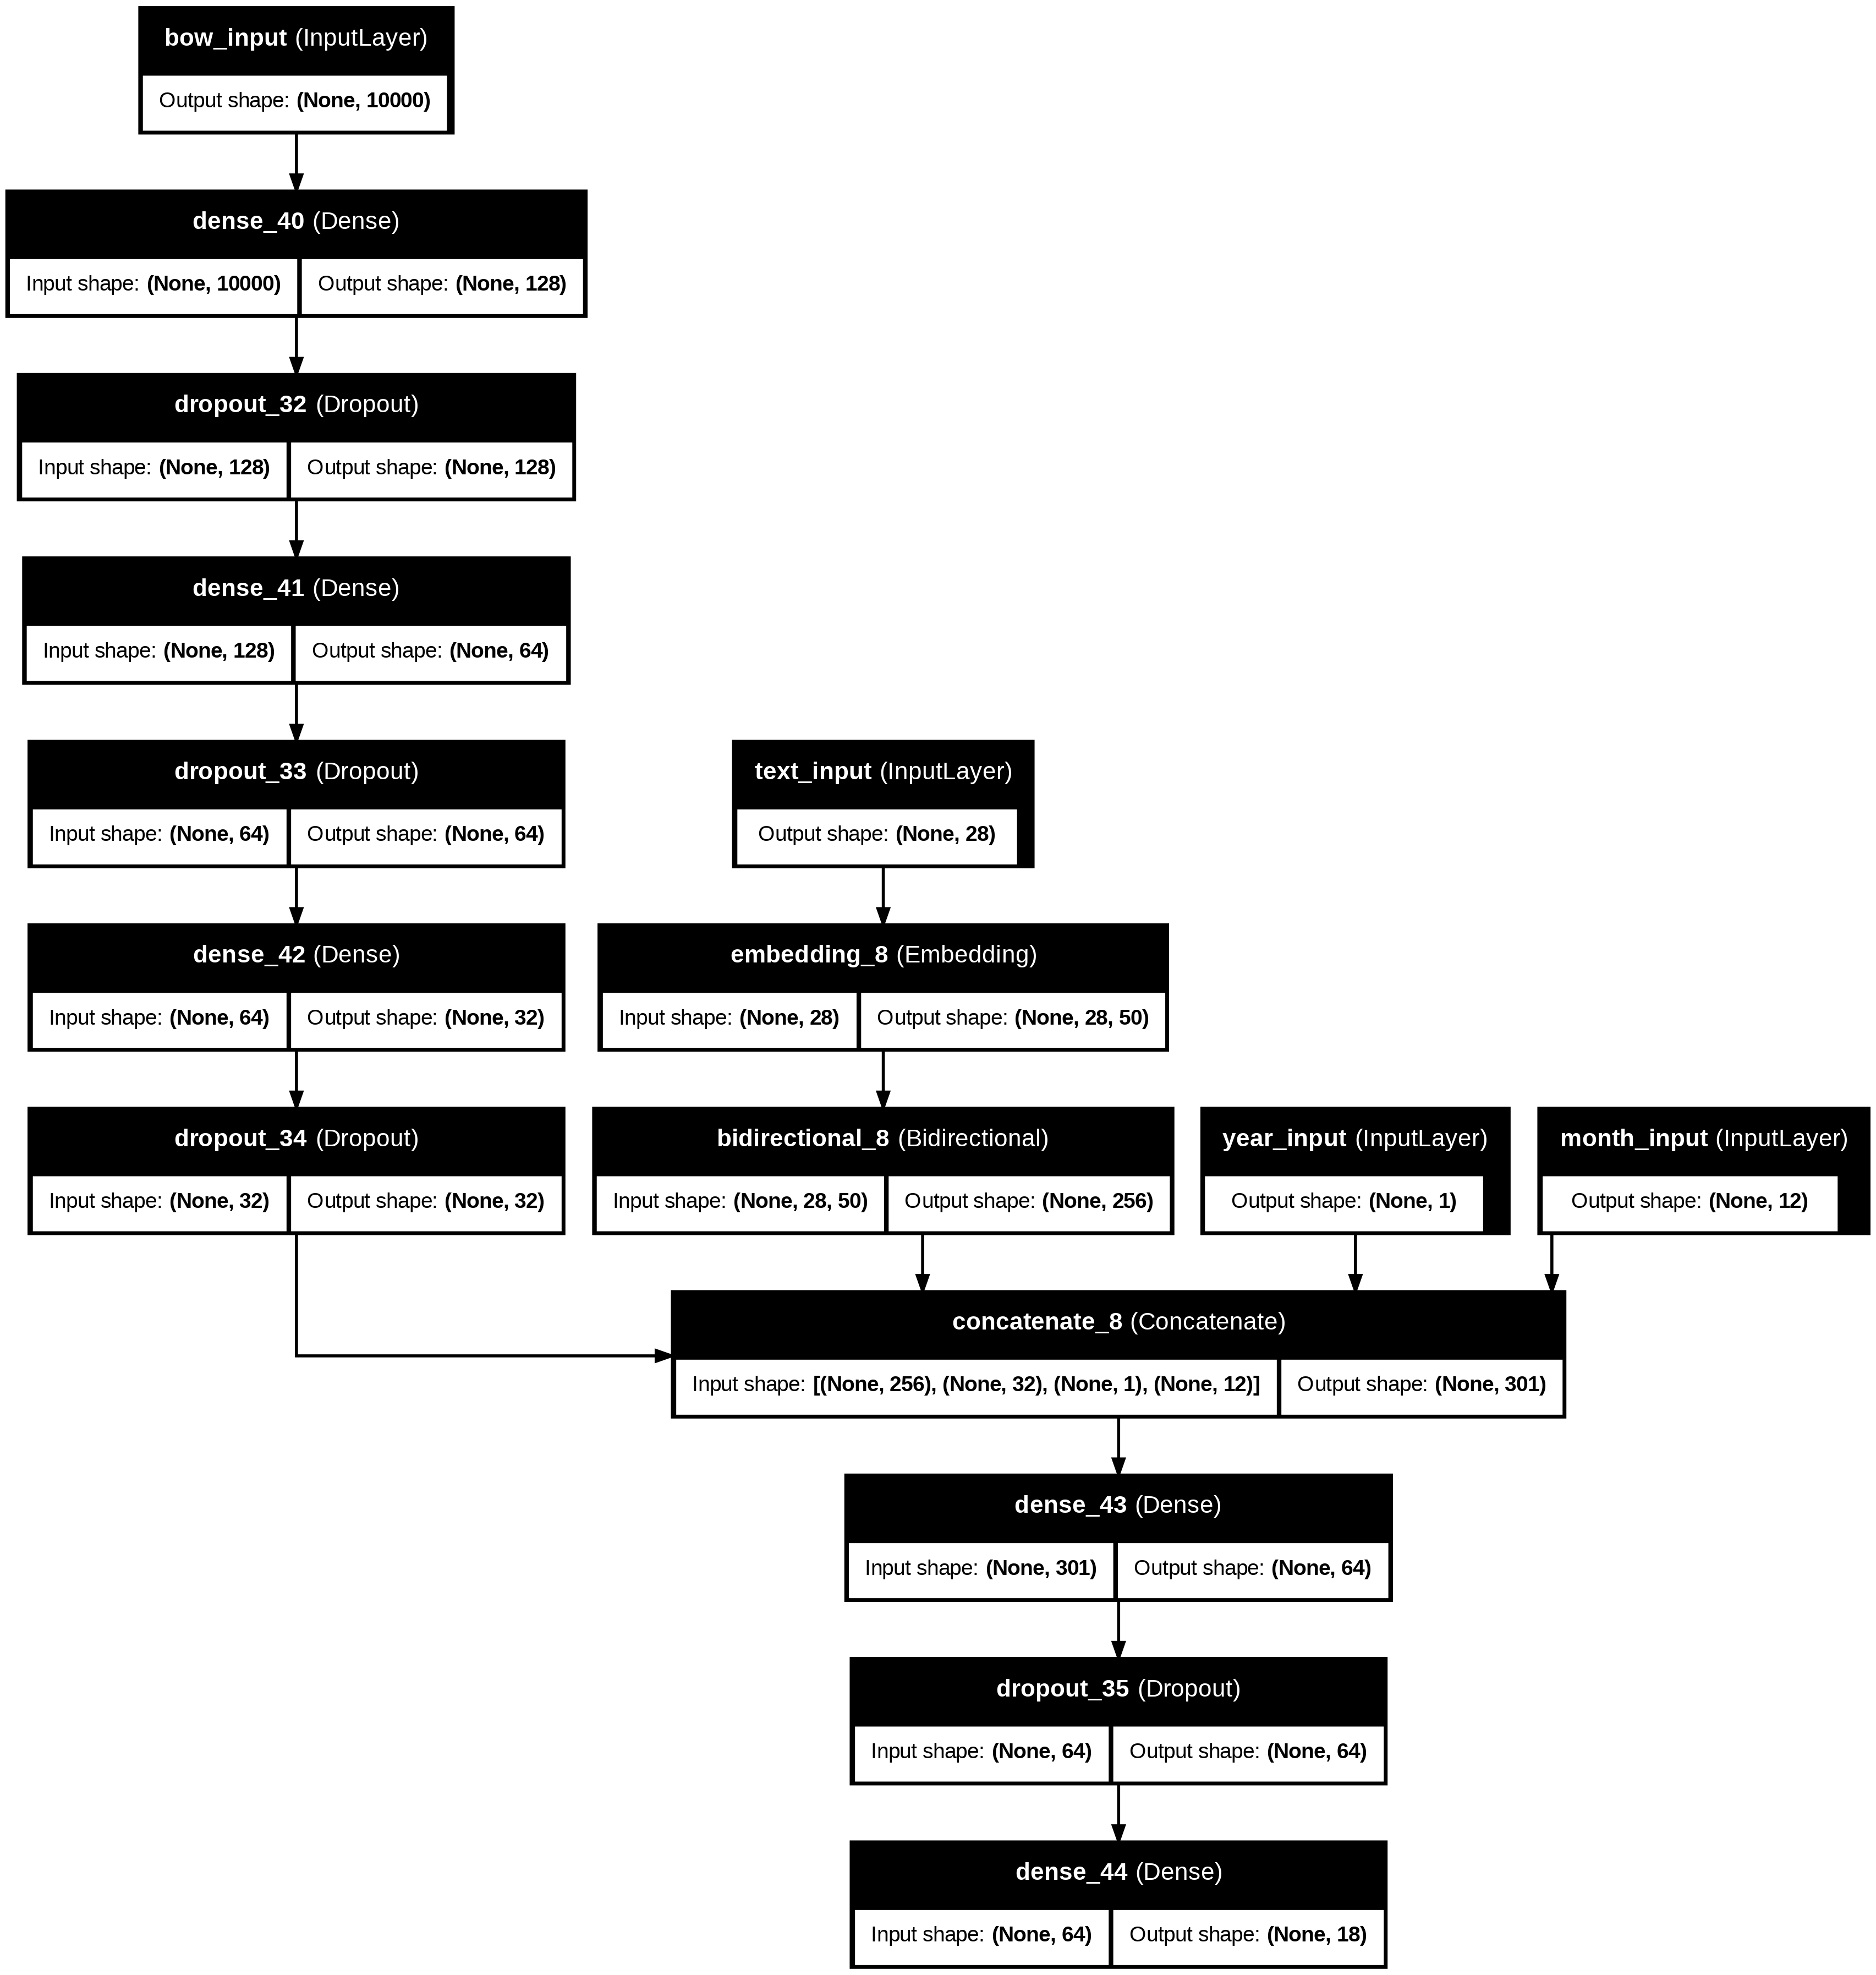

In [ ]:
#Graphical sketch
plot_model(model, show_shapes=True, show_layer_names=True, to_file="model_architecture.png")

In [ ]:
# Final training of the best model on train, with Early Stopping (restores best-val-loss weights)
train_arrays = [train_inputs["text_input"], train_inputs["bow_input"], train_inputs["year_input"], train_inputs["month_input"]]
val_arrays   = [val_inputs["text_input"], val_inputs["bow_input"], val_inputs["year_input"], val_inputs["month_input"]]

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)

setRandomSeed(seed)
history = model.fit(
    train_arrays, Y_train,
    validation_data=(val_arrays, Y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - f1_score: 0.0601 - loss: 0.3956 - val_f1_score: 0.0591 - val_loss: 0.3102
Epoch 2/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - f1_score: 0.1445 - loss: 0.2979 - val_f1_score: 0.1913 - val_loss: 0.2511
Epoch 3/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - f1_score: 0.4160 - loss: 0.2086 - val_f1_score: 0.5501 - val_loss: 0.2125
Epoch 4/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - f1_score: 0.7131 - loss: 0.1332 - val_f1_score: 0.6613 - val_loss: 0.2264
Epoch 5/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - f1_score: 0.8432 - loss: 0.0865 - val_f1_score: 0.6819 - val_loss: 0.2401
Epoch 6/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - f1_score: 0.8995 - loss: 0.0589 - val_f1_score: 0.6930 - val_loss: 0.2709
Epoch 7/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - f1_score: 0.9325 - loss: 0.0423 - val_f1_score: 0.6775 - val_loss: 0.3069
Epoch 8/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - f1_score: 0.9492 - loss: 0.0330 - val_f1_s

I train the model with the best hyperparameters found by the grid search on the training set, and I use the validation set to monitor it. I set a high maximum number of epochs, but Early Stopping (on
the validation loss, with restore_best_weights) stops the training automatically once the validation loss stops improving, and rolls the weights back to the best epoch. So I don't have to fix the number
of epochs by hand, and I avoid training into the overfitting region.

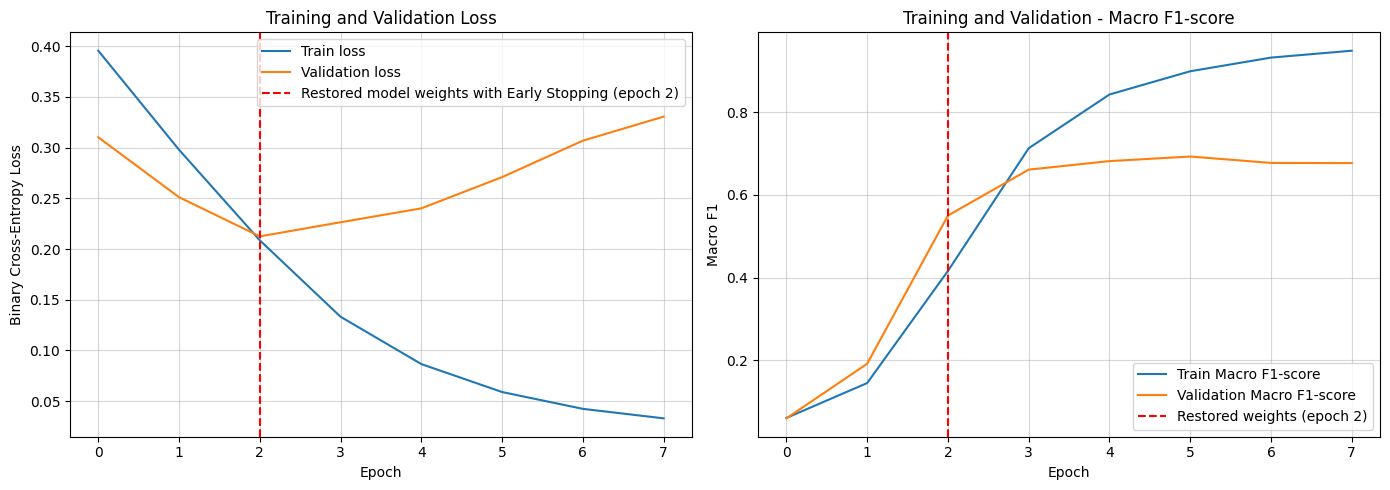

In [ ]:
# Learning curves: train/validation loss and Macro F1 per epoch, with the restored epoch
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

best_epoch = int(np.argmin(history.history['val_loss']))

axes[0].plot(history.history['loss'], label='Train loss')
axes[0].plot(history.history['val_loss'], label='Validation loss')
axes[0].axvline(best_epoch, color='red', linestyle='--',
                label=f'Restored model weights with Early Stopping (epoch {best_epoch})')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].set_title('Training and Validation Loss'); axes[0].legend(); axes[0].grid(alpha=0.5)

axes[1].plot(history.history['f1_score'], label='Train Macro F1-score')
axes[1].plot(history.history['val_f1_score'], label='Validation Macro F1-score')
axes[1].axvline(best_epoch, color='red', linestyle='--',
                label=f'Restored weights (epoch {best_epoch})')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Macro F1')
axes[1].set_title('Training and Validation - Macro F1-score'); axes[1].legend(); axes[1].grid(alpha=0.5)

plt.tight_layout(); plt.show()

The training loss keeps going down while the validation loss first decreases and then rises: this is overfitting. After a few epochs the model starts memorizing the training data.

The macro-F1 plot tells the same story from the other side: the training F1 keeps increasing while the validation F1 rises and then flattens.

Early Stopping with restore_best_weights handles this: the red line marks the epoch with the lowest validation loss, and the model is rolled back to that point instead of the later, overfitted epochs.

# 5. MODEL EVALUATION

I will evaluate the generalization and performance of the model on the held-out test defined in the split above (10% of the data, never used during training or hyperparameter tuning) once at the very end to avoid data leakage.

For the evaluation metrics, I use Macro F1-score besides accuracy, since the dataset is not perfectly balanced across the 18 subjects (class sizes range from about 1000 to 4000 samples), so accuracy alone could be misleading. F1 score combines both precision and recall into a single value (their harmonic mean), so it counts both false positives and false negatives, not only the correct predictions. Macro F1 averages the per-class F1 with equal weight for each class. This way frequent classes don't dominate the score. I also report the per-class confusion matrices to inspect the specific types of errors the model makes on each label.

I don't use any K-Fold cross validation since the dataset (N = 11000) is large enough for a single held-out split to give a reliable estimate of generalization performance.

In [ ]:
#Test-set evaluation -> per-class Accuracy/Precision/Recall/F1 (threshold 0.5) + their macro-averages
test_arrays = [test_inputs["text_input"], test_inputs["bow_input"], test_inputs["year_input"], test_inputs["month_input"]]

test_pred = model.predict(test_arrays, verbose=0)
test_pred_bin = (test_pred >= 0.5).astype(int)

f1_per_class        = f1_score(Y_test, test_pred_bin, average=None)
precision_per_class = precision_score(Y_test, test_pred_bin, average=None, zero_division=0)
recall_per_class    = recall_score(Y_test, test_pred_bin, average=None, zero_division=0)
accuracy_per_class  = (Y_test == test_pred_bin).mean(axis=0)

print("Per-class metrics:")
print(f"{'Class':>6} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1':>10}")
for i in range(NUM_LABELS):
    print(f"{i:>6} {accuracy_per_class[i]:>10.3f} {precision_per_class[i]:>10.3f} {recall_per_class[i]:>10.3f} {f1_per_class[i]:>10.3f}")

print(f"\nMacro-average Accuracy: {accuracy_per_class.mean():.3f}")
print(f"Macro-average Precision: {precision_per_class.mean():.3f}")
print(f"Macro-average Recall: {recall_per_class.mean():.3f}")
print(f"Macro-average F1-score: {f1_per_class.mean():.3f}")

Per-class metrics:
 Class   Accuracy  Precision     Recall         F1
     0      0.914      0.810      0.281      0.417
     1      0.924      1.000      0.106      0.192
     2      0.909      0.920      0.190      0.315
     3      0.924      1.000      0.106      0.192
     4      0.958      0.808      0.648      0.720
     5      0.913      0.821      0.264      0.400
     6      0.945      0.982      0.474      0.639
     7      0.818      0.620      0.277      0.383
     8      0.942      0.716      0.618      0.663
     9      0.858      0.840      0.741      0.787
    10      0.923      0.776      0.788      0.781
    11      0.949      0.850      0.405      0.548
    12      0.895      0.701      0.667      0.683
    13      0.915      0.452      0.322      0.376
    14      0.915      0.897      0.224      0.359
    15      0.940      0.720      0.578      0.641
    16      0.945      0.673      0.429      0.524
    17      0.919      0.755      0.798      0.776

Macro-avera

Per-class accuracy is high for every label, but it is misleading: each subject is absent in most news, so predicting "absent" is right most of the time. This is why I rely on macro-F1, not on accuracy.

The model is not equally good on all subjects: some classes are clearly easier than others, and macro-F1 (equal weight per class) reflects this spread.

With a fixed 0.5 threshold, precision tends to be higher than recall: the model is cautious and misses some true labels instead of over-predicting them.

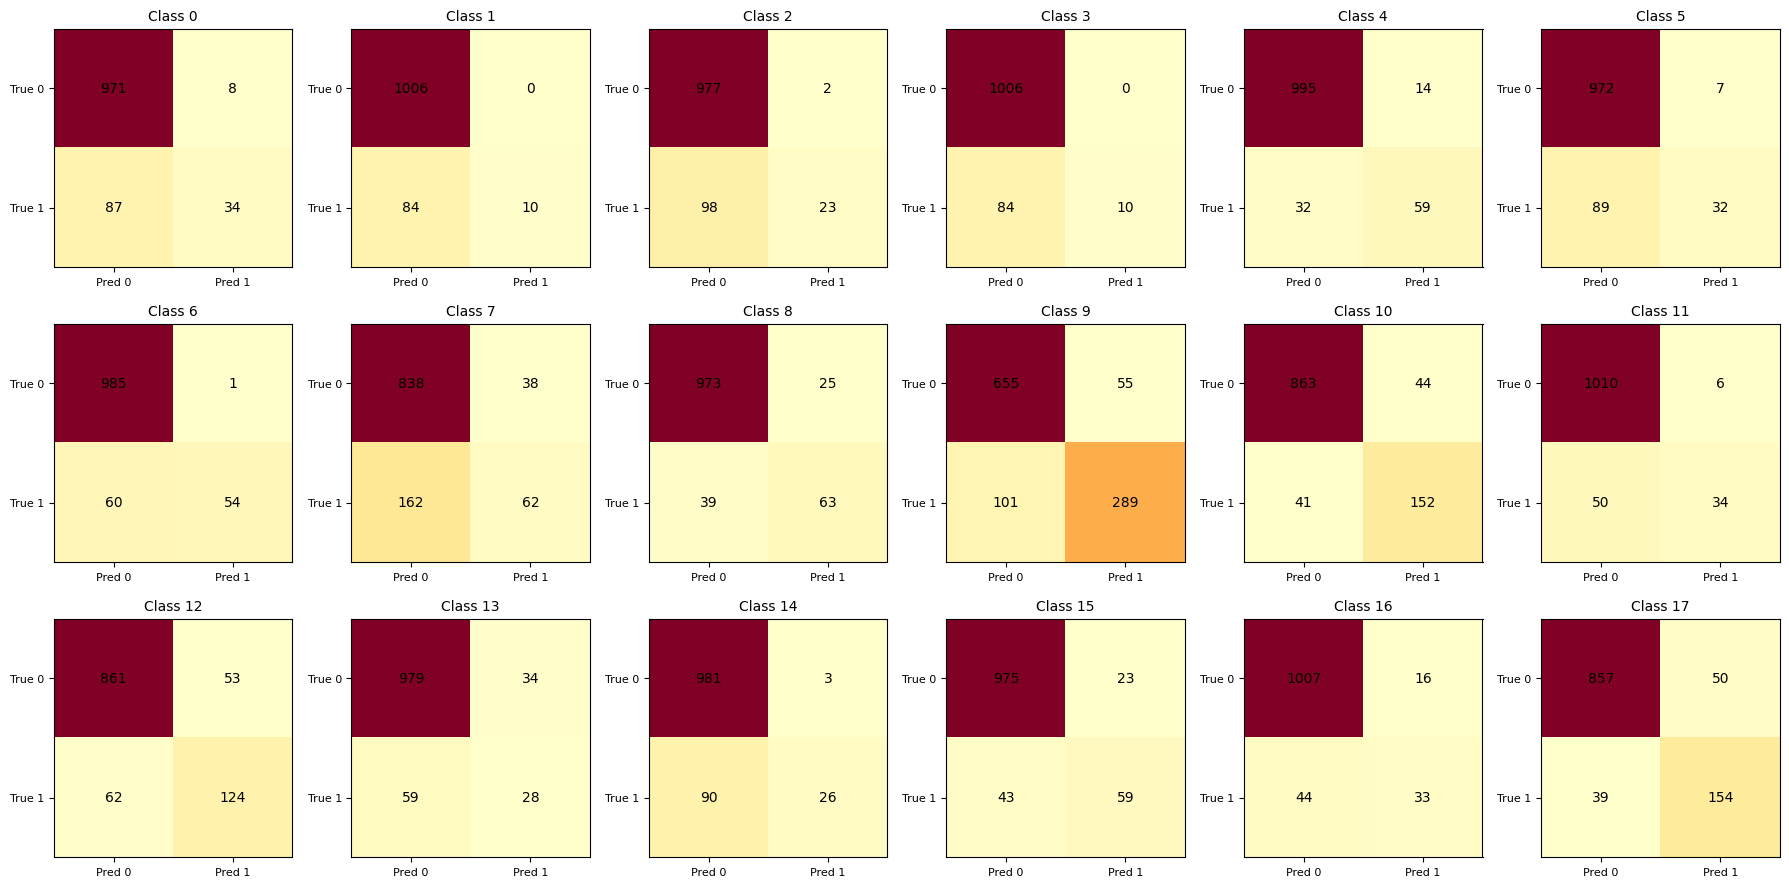

In [ ]:
#Per-class confusion matrices on the test set
conf_matrices = multilabel_confusion_matrix(Y_test, test_pred_bin)

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for i, ax in enumerate(axes.flat):
    cm = conf_matrices[i]
    ax.imshow(cm, cmap='YlOrRd')
    for r in range(2):
        for c in range(2):
            ax.text(c, r, cm[r, c], ha='center', va='center')
    ax.set_title(f'Class {i}', fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Pred 0', 'Pred 1'], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(['True 0', 'True 1'], fontsize=8)

plt.tight_layout()
plt.show()

For each of the 18 labels I show a 2x2 confusion matrix (TN / FP / FN / TP), so I can inspect what kind of errors the model makes on each subject.

- The true-negative cell (top-left) is by far the largest in every matrix, because each subject is
  absent in most news. This is the same class imbalance that makes accuracy look high.
- For each label the matrix shows whether the errors are mostly false positives (right column) or
  false negatives (bottom-left), which is more informative than a single accuracy value.